# DSCI 552 — Homework 6

**Name:** Ellie He
**Course:** DSCI 552 — Machine Learning for Data Science (Instructor: Mohammad Reza Rajati)
**Assignment:** Homework 6 — Tree-Based Methods, Class Imbalance, and SMOTE

**Contents**
1. Tree-Based Methods on the APS Failure at Scania Trucks dataset (parts a–f)
2. ISLR 6.6.3
3. ISLR 6.6.5
4. ISLR 8.4.5
5. ISLR 9.7.3

**Execution environment:** Python 3.12.14; scikit-learn 1.8.0; XGBoost 3.4.1; imbalanced-learn 0.14.2; pandas 2.2.3; NumPy 2.3.5. All model results were recomputed; the OOB coverage calculation was separately verified with the same balanced-forest settings.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             accuracy_score, recall_score, precision_score)
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
sns.set_style("whitegrid")

## 1. Tree-Based Methods

### (a) APS Failure data

The official training and test files contain a 20-line license header; `na` denotes a missing value. The loader searches the current directory and common data subdirectories.

In [2]:
candidates = [Path("."), Path("data"), Path("../data"), Path("upload"), Path("../upload")]
DATA_DIR = next((p for p in candidates if all((p / f).is_file() for f in
    ["aps_failure_training_set.csv", "aps_failure_test_set.csv"])), None)
if DATA_DIR is None:
    raise FileNotFoundError("Place the two APS CSV files beside the notebook or in data/.")
train_raw = pd.read_csv(f"{DATA_DIR}/aps_failure_training_set.csv", skiprows=20, na_values="na")
test_raw  = pd.read_csv(f"{DATA_DIR}/aps_failure_test_set.csv",     skiprows=20, na_values="na")

print("Training set shape:", train_raw.shape)
print("Test set shape:    ", test_raw.shape)
train_raw.head()

Training set shape: (60000, 171)
Test set shape:     (16000, 171)
Out[2]: 
  class  aa_000  ab_000        ac_000  ad_000  ae_000  af_000  ag_000  ag_001  ag_002  ag_003   ag_004     ag_005     ag_006     ag_007  \
0   neg   76698     NaN  2.130706e+09   280.0     0.0     0.0     0.0     0.0     0.0     0.0  37250.0  1432864.0  3664156.0  1007684.0   
1   neg   33058     NaN  0.000000e+00     NaN     0.0     0.0     0.0     0.0     0.0     0.0  18254.0   653294.0  1720800.0   516724.0   
2   neg   41040     NaN  2.280000e+02   100.0     0.0     0.0     0.0     0.0     0.0     0.0   1648.0   370592.0  1883374.0   292936.0   
3   neg      12     0.0  7.000000e+01    66.0     0.0    10.0     0.0     0.0     0.0   318.0   2212.0     3232.0     1872.0        0.0   
4   neg   60874     NaN  1.368000e+03   458.0     0.0     0.0     0.0     0.0     0.0     0.0  43752.0  1966618.0  1800340.0   131646.0   

   ...      eb_000    ec_00  ed_000    ee_000     ee_001     ee_002    ee_003    ee_004   

## (b) Data Preparation

### i. Missing values and data imputation

In [3]:
features = [c for c in train_raw.columns if c != "class"]
miss_tr = train_raw[features].isna().mean()
miss_te = test_raw[features].isna().mean()

print(f"Number of features: {len(features)}")
print(f"Training rows with at least one missing value: {train_raw[features].isna().any(axis=1).sum()} "
      f"of {len(train_raw)} ({train_raw[features].isna().any(axis=1).mean():.1%})")
print(f"Overall fraction of missing cells (train): {train_raw[features].isna().values.mean():.2%}")
print(f"Features with > 50% missing (train): {(miss_tr > 0.5).sum()}")
print(f"Features with no missing values (train): {(miss_tr == 0).sum()}")

miss_tr.sort_values(ascending=False).head(10).to_frame("fraction missing (train)")

Number of features: 170
Training rows with at least one missing value: 59409 of 60000 (99.0%)
Overall fraction of missing cells (train): 8.33%
Features with > 50% missing (train): 8
Features with no missing values (train): 1
Out[3]: 
        fraction missing (train)
br_000                  0.821067
bq_000                  0.812033
bp_000                  0.795667
bo_000                  0.772217
ab_000                  0.772150
cr_000                  0.772150
bn_000                  0.733483
bm_000                  0.659150
bl_000                  0.454617
bk_000                  0.383900


**Common techniques for dealing with missing values (data imputation):**

| Technique | Idea | Notes |
|---|---|---|
| Listwise / pairwise deletion | Drop rows (or use only complete pairs) with missing values | Simple, but wastes data and biases results unless data are missing completely at random. Here almost every row has a missing value, so deletion is not an option. |
| Dropping features | Remove columns with a very high missing rate | Loses information; sometimes "missingness" is itself informative. |
| Mean / median / mode imputation | Replace each missing value with a summary statistic of the feature | Fast and simple. The median is robust to skewed data and outliers. Reduces variance and ignores relationships between features. |
| Constant + missing-indicator | Fill with a constant (e.g. 0 or −1) and add a binary "was missing" flag | Lets tree models learn from the missingness pattern. |
| Hot-deck imputation | Fill with an observed value from a similar record | Keeps realistic values. |
| k-nearest-neighbors imputation | Average the feature over the k most similar rows | Uses relationships between features; expensive on large data. |
| Regression imputation | Predict the missing feature from the other features | Uses correlations; can understate uncertainty. |
| Multiple imputation (e.g. MICE) | Iteratively model each feature from the others; repeat several times | Repeated stochastic imputations represent uncertainty; one deterministic iterative-imputer run is not multiple imputation. |
| EM / model-based imputation | Fit a probabilistic model (e.g. multivariate Gaussian) by maximum likelihood | Principled, but relies on distributional assumptions. |
| Tree-based imputation (e.g. missForest) / native handling | Random-forest imputation, or algorithms such as XGBoost that learn a default direction for missing values | Handles nonlinearity and mixed types. |

**Method used: median imputation.** All features are non-negative counters and histogram bins with very heavy right tails (CVs are large, see part ii), so median imputation provides a simple fill value that is robust to extreme observations. Following the footnote, the training set is imputed with training-set medians and the test set is imputed with test-set medians.

For cross-validation, the original, unfilled training features are retained. Each fold fits its imputer using only that fold's training rows. The assignment's separate test-median convention is retained for the final held-out test set; in standard deployment, a saved training-fitted imputer would normally be reused.

In [4]:
X_train_raw = train_raw[features].copy()
X_train = X_train_raw.copy()
X_test  = test_raw[features].copy()
y_train = (train_raw["class"] == "pos").astype(int).values
y_test  = (test_raw["class"]  == "pos").astype(int).values

# Median imputation: training set filled with training medians,
# test set filled with test medians (as instructed in the footnote).
X_train = X_train.fillna(X_train.median())
X_test  = X_test.fillna(X_test.median())

print("Missing values left (train, test):", X_train.isna().sum().sum(), X_test.isna().sum().sum())

Missing values left (train, test): 0 0


### ii. Coefficient of variation

$CV = s/m$, where $s$ is the sample standard deviation and $m$ is the sample mean, computed on the imputed training set.

In [5]:
cv = (X_train.std(ddof=1) / X_train.mean()).rename("CV")
cv_table = cv.to_frame()
cv_table["mean"] = X_train.mean()
cv_table["std"] = X_train.std(ddof=1)
cv_table = cv_table.sort_values("CV", ascending=False)

print("Features whose CV is undefined or 0 (zero variance):",
      list(cv_table.index[(cv_table['std'] == 0) | cv_table['CV'].isna()]))
with pd.option_context("display.max_rows", 200, "display.float_format", "{:.4f}".format):
    display(cv_table[["CV"]])

Features whose CV is undefined or 0 (zero variance): ['cd_000']


,CV
cf_000,244.8875
co_000,244.5074
ad_000,244.3228
cs_009,237.9306
dh_000,123.2161
dj_000,117.4942
ag_000,92.9178
as_000,87.3325
ay_009,84.7337
ak_000,80.4250


### iii. Correlation matrix

Feature pairs with |r| > 0.9: 130 of 14196
Most correlated pairs:
bv_000  cq_000    1.0000
bu_000  cq_000    1.0000
        bv_000    1.0000
cf_000  co_000    1.0000
ad_000  cf_000    1.0000
        co_000    1.0000
aa_000  bt_000    0.9988
ah_000  bg_000    0.9977
bb_000  bv_000    0.9963
        bu_000    0.9963
dtype: float64


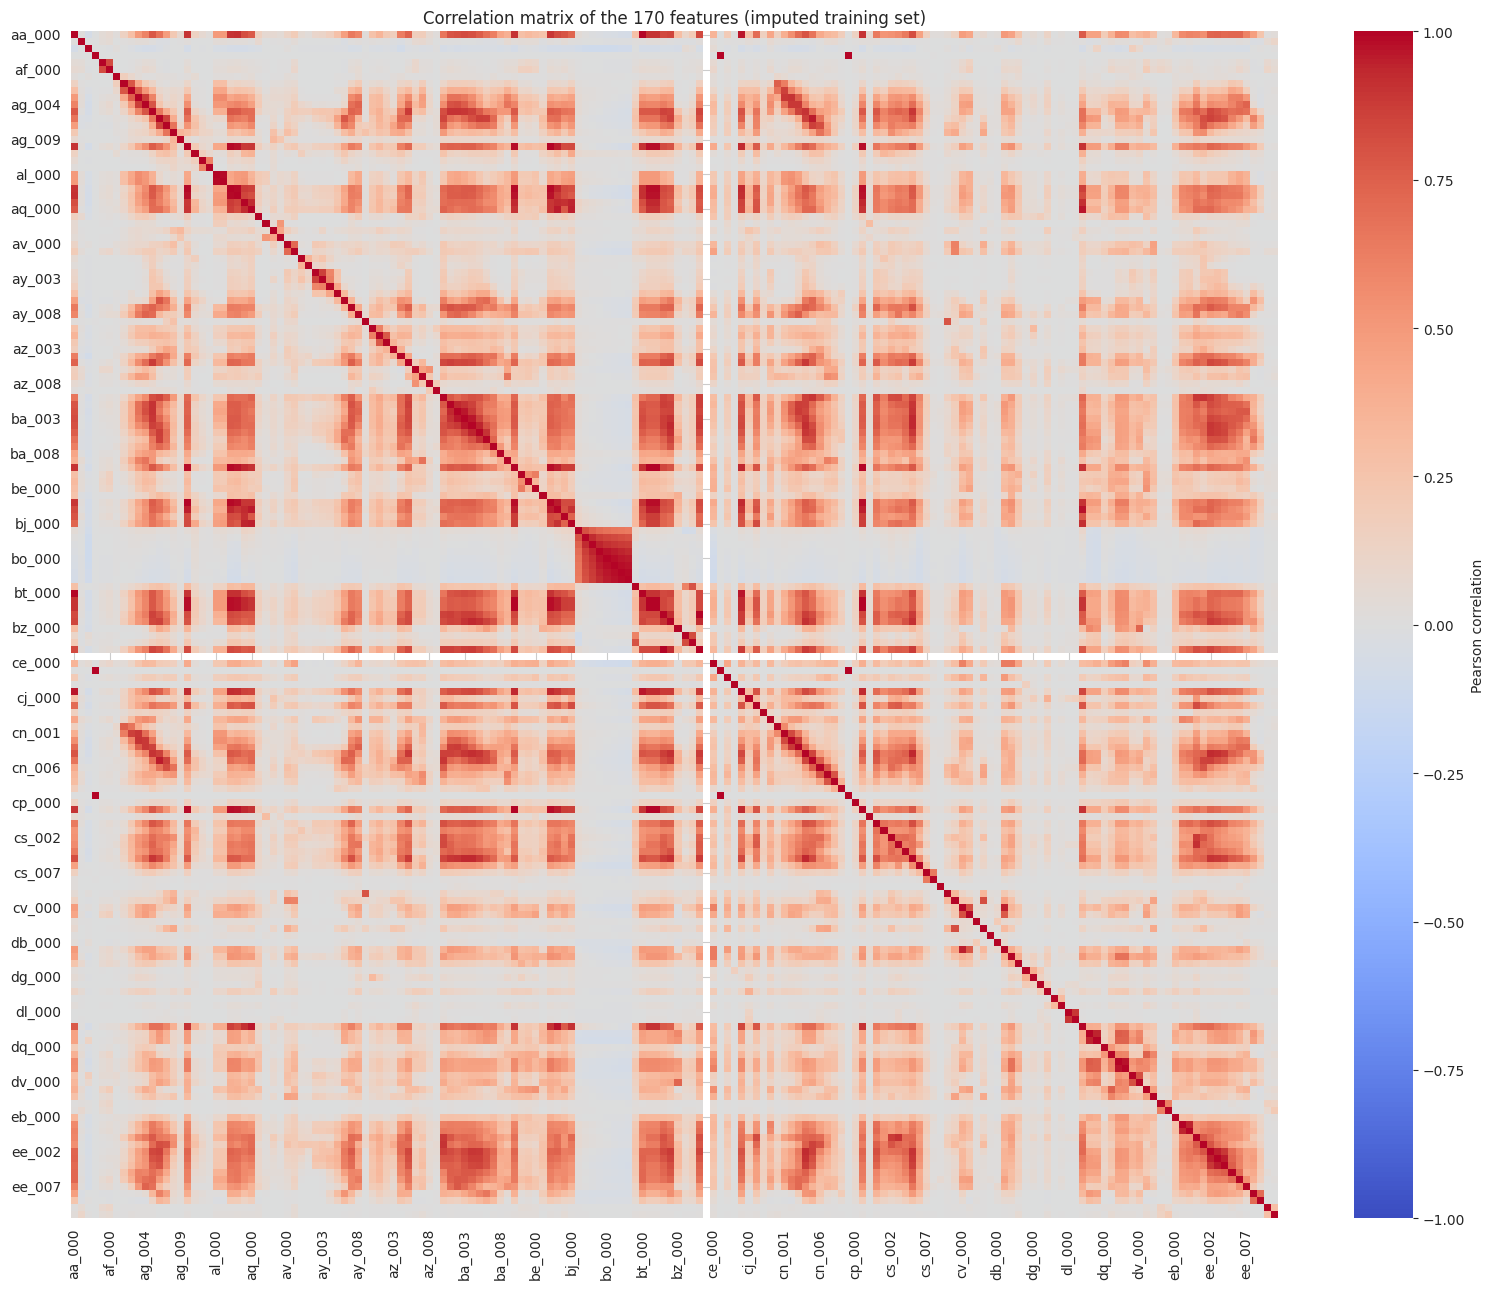

In [6]:
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            xticklabels=5, yticklabels=5, ax=ax, cbar_kws={"label": "Pearson correlation"})
ax.set_title("Correlation matrix of the 170 features (imputed training set)")
plt.tight_layout(); plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().dropna()
print(f"Feature pairs with |r| > 0.9: {(upper.abs() > 0.9).sum()} of {len(upper)}")
print("Most correlated pairs:")
print(upper.abs().sort_values(ascending=False).head(10).round(4))

**Observations.** Most of the 170 features are positively correlated with each other (warm colors dominate), which makes sense because many of them are counters and histogram bins that all grow with how much a truck has been used. There are blocks of strongly correlated features, especially among the histogram families (e.g. `ag_*`, `ay_*`, `az_*`, `cn_*`, `cs_*`, `ee_*`), and 130 feature pairs have $|r|>0.9$. Several pairs are perfectly or almost perfectly correlated (for example `bu_000`, `bv_000` and `cq_000`; `ad_000`, `cf_000` and `co_000`; `aa_000` and `bt_000`). So the features are highly redundant. Tree-based models can accommodate correlated predictors, but it means that individual feature importances should be interpreted carefully. The white row/column is `cd_000`, which is constant, so its correlations are undefined. There is also a separate block of features `bk_000`–`br_000` (the features with 38–82% missing values) that are strongly correlated with each other but almost uncorrelated with everything else; median imputation may affect this pattern, but the plot alone does not identify its cause.

### iv. Scatter plots and box plots for the $\lfloor\sqrt{170}\rfloor = 13$ features with the highest CV

In [7]:
k = int(np.floor(np.sqrt(170)))
top_cv = cv_table.index[:k].tolist()
print(f"k = {k}; features with highest CV:")
print(cv_table.loc[top_cv, ["CV"]].round(3).T)

k = 13; features with highest CV:
     cf_000   co_000   ad_000   cs_009   dh_000   dj_000  ag_000  as_000  ay_009  ak_000  az_009  ch_000  au_000
CV  244.888  244.507  244.323  237.931  123.216  117.494  92.918  87.332  84.734  80.425  77.839  77.454  68.883


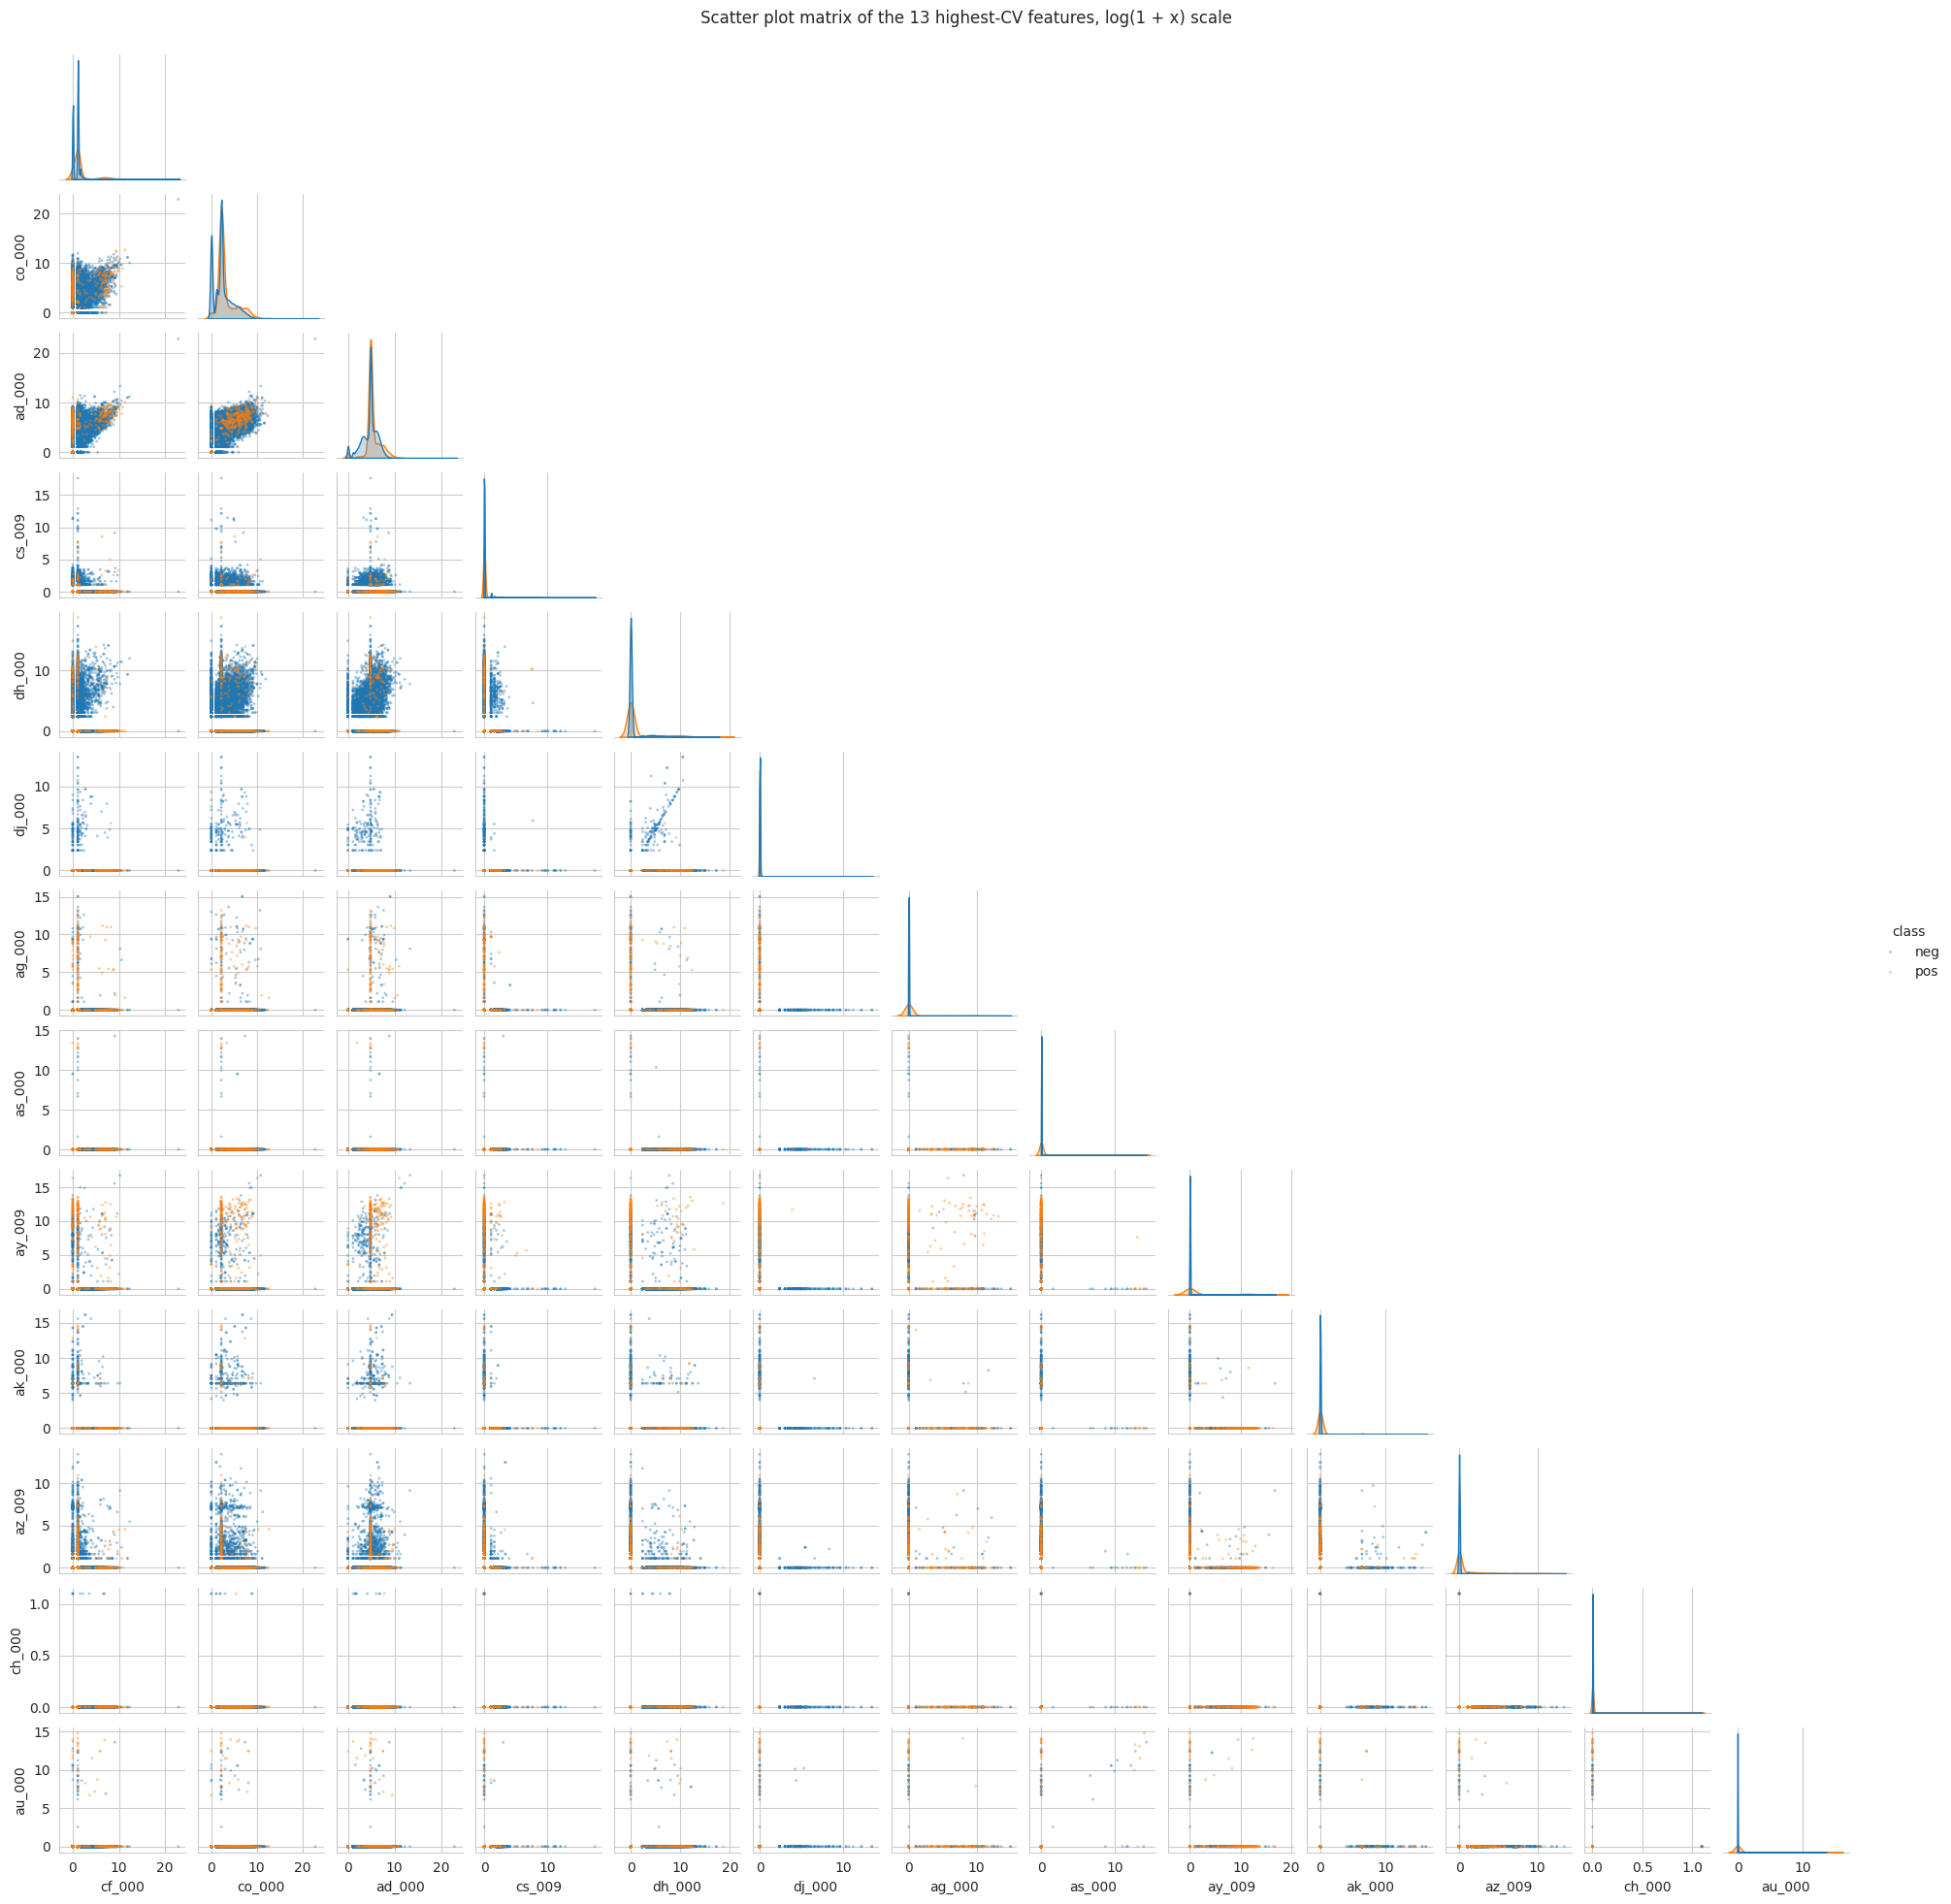

In [8]:
# The raw features are heavily right-skewed counts, so the plots use log(1 + x)
# to make the two classes visible. Positives are drawn on top of negatives.
viz = np.log1p(X_train[top_cv].clip(lower=0))
viz["class"] = np.where(y_train == 1, "pos", "neg")
viz = pd.concat([viz[viz["class"] == "neg"], viz[viz["class"] == "pos"]])

g = sns.pairplot(viz, vars=top_cv, hue="class", hue_order=["neg", "pos"],
                 palette={"neg": "tab:blue", "pos": "tab:orange"},
                 plot_kws={"s": 4, "alpha": 0.4, "linewidth": 0, "rasterized": True},
                 diag_kind="kde", diag_kws={"common_norm": False}, corner=True, height=1.5)
g.fig.suptitle("Scatter plot matrix of the 13 highest-CV features, log(1 + x) scale", y=1.01)
plt.show()

Out[9]: 
        mean (neg)  mean (pos)  % non-zero (neg)  % non-zero (pos)
cf_000   145524.46      508.77             63.96              79.6
co_000   145734.70     1453.65             78.38              96.4
ad_000   145854.46      884.36             96.64              97.3
cs_009      783.39       10.73              4.83               5.2
dh_000     2273.77   129405.91             11.64              11.9
dj_000       37.90        0.33              0.33               0.2
ag_000      186.41     2151.29              0.17               9.7
as_000       63.91     3753.97              0.03               0.6
ay_009      612.56    32836.25              0.56              20.7
ak_000      795.97     7497.60              0.58               3.1
az_009       40.53      104.67              2.89              17.7
ch_000        0.00        0.00              0.02               0.1
au_000       41.71    11228.66              0.06               2.6


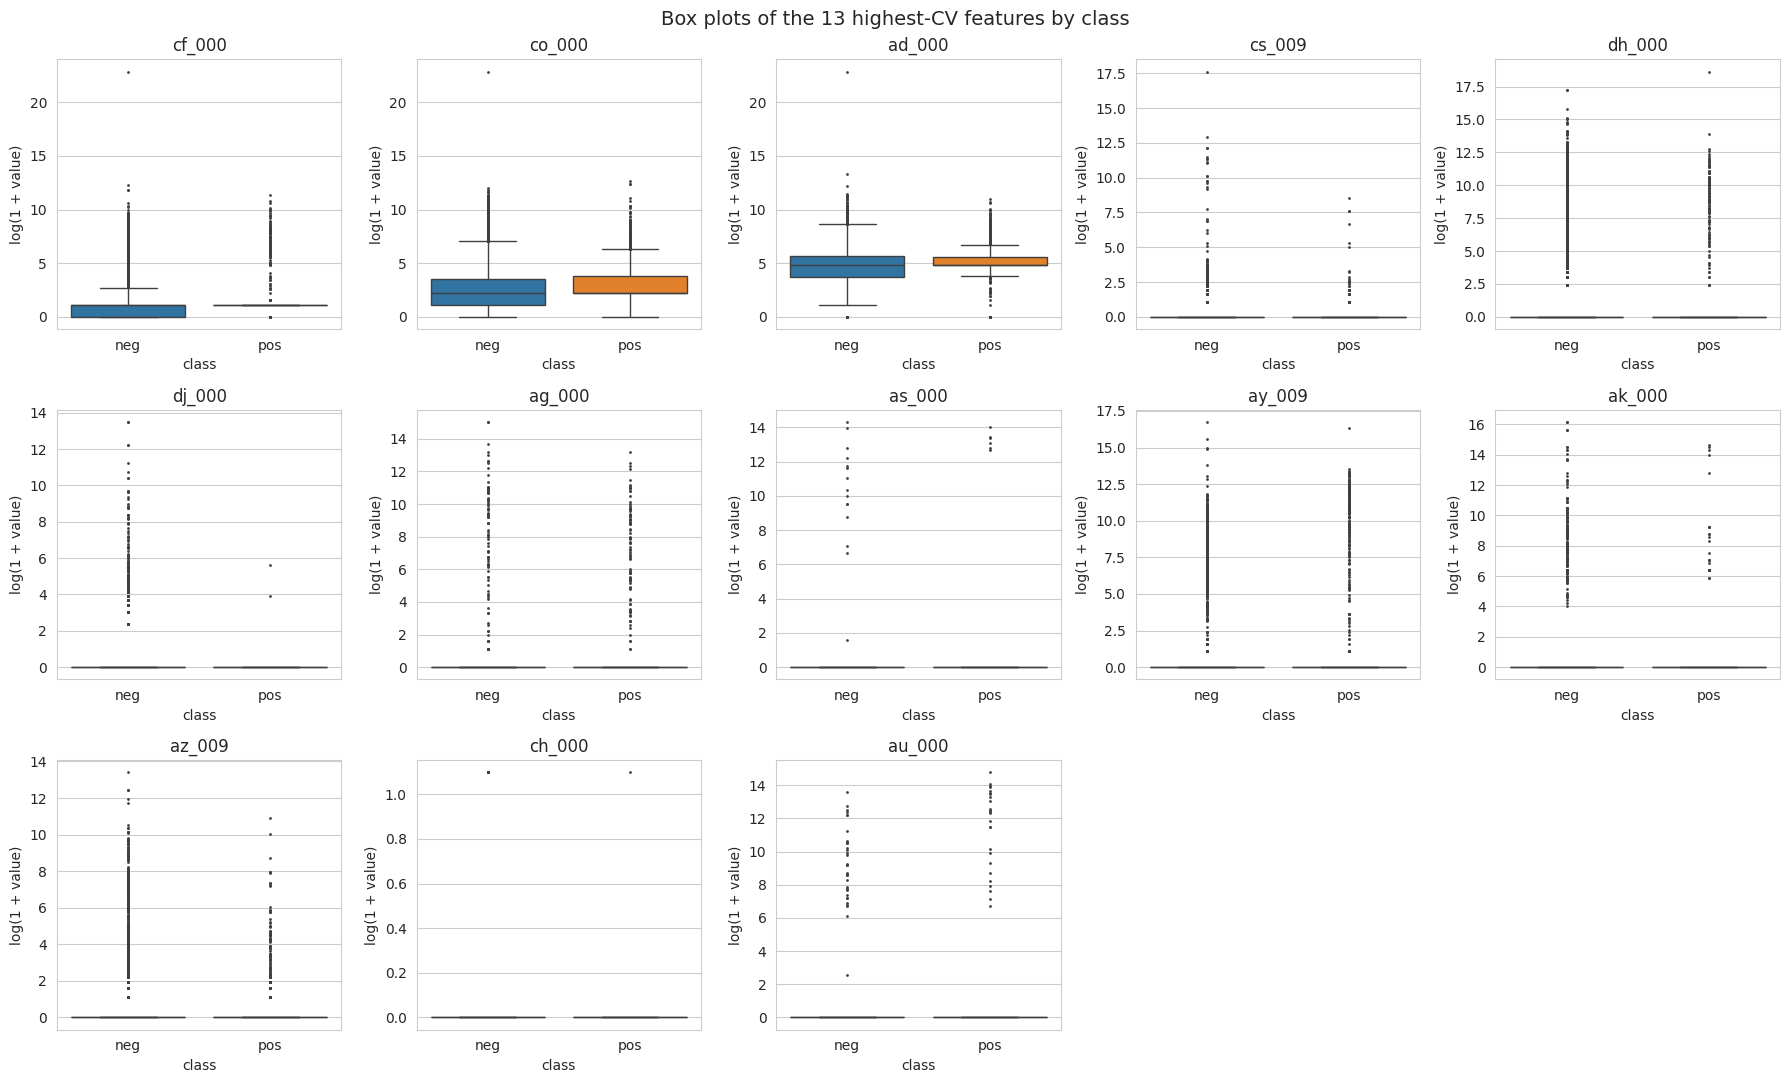

In [9]:
fig, axes = plt.subplots(3, 5, figsize=(18, 11))
for ax, f in zip(axes.ravel(), top_cv):
    sns.boxplot(x=np.where(y_train == 1, "pos", "neg"), y=np.log1p(X_train[f].clip(lower=0)),
                order=["neg", "pos"], palette={"neg": "tab:blue", "pos": "tab:orange"},
                ax=ax, fliersize=1)
    ax.set_title(f); ax.set_xlabel("class"); ax.set_ylabel("log(1 + value)")
for ax in axes.ravel()[k:]:
    ax.axis("off")
fig.suptitle("Box plots of the 13 highest-CV features by class", fontsize=14)
plt.tight_layout(); plt.show()

# Class-wise summaries on the original scale (most values are 0, so medians are uninformative)
summ = pd.DataFrame({"mean (neg)": X_train.loc[y_train == 0, top_cv].mean(),
                     "mean (pos)": X_train.loc[y_train == 1, top_cv].mean(),
                     "% non-zero (neg)": 100 * (X_train.loc[y_train == 0, top_cv] > 0).mean(),
                     "% non-zero (pos)": 100 * (X_train.loc[y_train == 1, top_cv] > 0).mean()})
summ.round(2)

**Can we draw conclusions about significance from the scatter plots alone? No, not reliably.**

- For most of these 13 features the vast majority of values are exactly 0 in **both** classes: for 10 of the 13 features the median is 0 in both classes and the boxes collapse to a line at 0 (and for `cf_000`, `co_000` and `ad_000` the class medians are also equal). A very high CV here mostly reflects a few extreme values, not a difference between the classes. For example, the negative-class means of `cf_000`, `co_000` and `ad_000` are dominated by a single huge outlier.
- Some features do *suggest* a relationship with the positive class: `ag_000`, `ay_009`, `az_009`, `ak_000`, `as_000` and `au_000` are non-zero much more often for positive trucks (e.g. `ay_009` is non-zero for about 21% of positives versus 0.6% of negatives), and in the `ay_009` vs `co_000`/`ad_000` panels the positives form a visible cluster. `co_000` and `ad_000` are also slightly shifted upward for positives in the box plots.
- Other features (`cs_009`, `dj_000`, `ch_000`, `dh_000`) show no visible separation.

However, the classes overlap heavily in every panel, the positive class is only 1.7% of the points, and a 2-D scatter plot cannot show interactions with the other 157 features or account for the strong correlations between features. Visual impressions are therefore only hints. To judge significance we would need a formal approach (hypothesis tests such as a Mann–Whitney test, a fitted model with standard errors, or variable importance from a model evaluated on held-out data). Also, high CV is a measure of spread, not of predictive power, so these are not necessarily the most important features.

### v. Number of positive and negative data

In [10]:
counts = pd.DataFrame({
    "train": pd.Series(y_train).map({0: "neg", 1: "pos"}).value_counts(),
    "test":  pd.Series(y_test).map({0: "neg", 1: "pos"}).value_counts(),
})
counts.loc["positive fraction"] = counts.loc["pos"] / counts.loc[["neg", "pos"]].sum()
counts

Out[10]: 
                          train          test
neg                59000.000000  15625.000000
pos                 1000.000000    375.000000
positive fraction      0.016667      0.023438


**Training set:** 59,000 negative and 1,000 positive examples (1.67% positive).  
**Test set:** 15,625 negative and 375 positive examples (2.34% positive).

**Yes, the dataset is highly imbalanced** (about 59 : 1 in the training set). A trivial classifier that always predicts "neg" would already have only 1.67% training error and 2.34% test error, so misclassification rate alone is a misleading metric here. The confusion matrix, recall of the positive class, ROC/AUC, and the cost from the dataset description are more informative.

### Helper functions for evaluation

All confusion matrices use the default threshold of 0.5 on the predicted probability of the positive class. Rows are true classes and columns are predicted classes. The dataset description also defines a misclassification cost (cost 10 for a false positive and 500 for a false negative); it is reported as an extra column.

In [11]:
results = {}   # summary table filled in by every model

def evaluate(model, name, X_tr=X_train, y_tr=y_train, X_te=X_test, y_te=y_test, threshold=0.5):
    """Print confusion matrices, AUC and misclassification on train and test; plot ROC curves."""
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    rows = []
    for (label, X, y), ax in zip([("Train", X_tr, y_tr), ("Test", X_te, y_te)], axes[:2]):
        p = model.predict_proba(X)[:, 1]
        pred = (p >= threshold).astype(int)
        cm = confusion_matrix(y, pred, labels=[0, 1])
        auc = roc_auc_score(y, p)
        err = 1 - accuracy_score(y, pred)
        tn, fp, fn, tp = cm.ravel()
        rows.append({"set": label, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                     "misclassification": err, "AUC": auc,
                     "recall (pos)": tp / (tp + fn), "precision (pos)": tp / max(tp + fp, 1),
                     "cost (10·FP + 500·FN)": 10 * fp + 500 * fn})
        sns.heatmap(pd.DataFrame(cm, index=["true neg", "true pos"], columns=["pred neg", "pred pos"]),
                    annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
        ax.set_title(f"{label} confusion matrix")
        fpr, tpr, _ = roc_curve(y, p)
        axes[2].plot(fpr, tpr, label=f"{label} (AUC = {auc:.4f})")
    axes[2].plot([0, 1], [0, 1], "k--", lw=1)
    axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate")
    axes[2].set_title("ROC curves"); axes[2].legend(loc="lower right")
    fig.suptitle(name, fontsize=13); plt.tight_layout(); plt.show()
    df = pd.DataFrame(rows).set_index("set")
    results[name] = df.loc["Test"]
    with pd.option_context("display.float_format", "{:.4f}".format):
        display(df)
    return df

## (c) Random forest without compensation for class imbalance

OOB error estimate: 0.0057
Test error:         0.0076


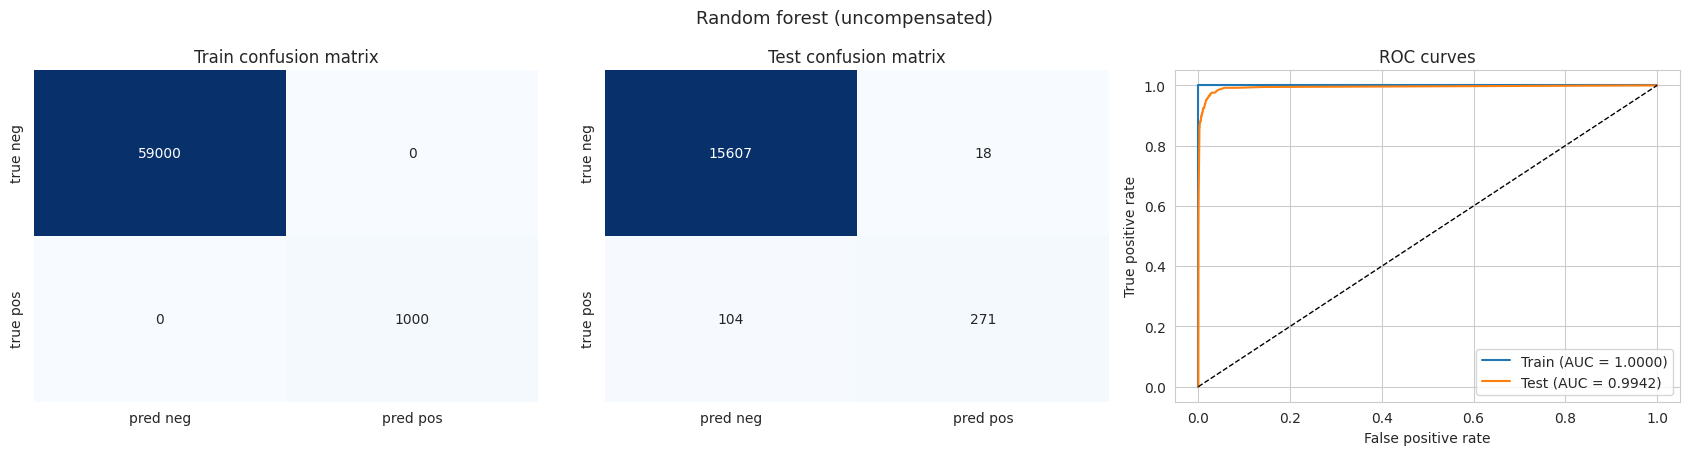

,TN,FP,FN,TP,misclassification,AUC,recall (pos),precision (pos),cost (10·FP + 500·FN)
set,,,,,,,,,
Train,59000,0,0,1000,0.0000,1.0000,1.0000,1.0000,0
Test,15607,18,104,271,0.0076,0.9942,0.7227,0.9377,52180


In [12]:
rf = RandomForestClassifier(n_estimators=300, max_features="sqrt", oob_score=True,
                            n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train)
rf_res = evaluate(rf, "Random forest (uncompensated)")

oob_err = 1 - rf.oob_score_
print(f"OOB error estimate: {oob_err:.4f}")
print(f"Test error:         {rf_res.loc['Test', 'misclassification']:.4f}")

**Results: uncompensated random forest**

| Model / set | TN | FP | FN | TP | Error | AUC | Recall | Cost |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Train | 59,000 | 0 | 0 | 1,000 | 0.00000 | 1.00000 | 1.0000 | 0 |
| Test | 15,607 | 18 | 104 | 271 | 0.00762 | 0.99422 | 0.7227 | 52,180 |

OOB error is **0.00573**, compared with test error **0.00762**. The training fit is optimistic; OOB evaluation is more informative about generalization. A difference in positive-class proportions (1.67% in training versus 2.34% in test) may contribute to the error gap, but these results alone cannot isolate its cause.

At the default threshold, the model misses 104 of 375 failures. Its high AUC indicates good ranking, while the confusion matrix shows the limitations of the default threshold for this imbalanced task. OOB evaluation uses features imputed with full-training medians, so it is an approximate estimate rather than an evaluation that also refits preprocessing for every OOB subset.

## (d) Compensating for class imbalance in random forests

**How class imbalance is addressed in random forests.** A standard random forest uses impurity-based splits and aggregates predictions without automatically assigning extra importance to the minority class. With 98% negatives, low overall error can coexist with poor minority-class recall. The common remedies are:

1. **Balanced random forest (down-sampling; Chen, Liaw & Breiman, 2004).** For each tree, draw a bootstrap sample from the minority class and the same number of cases from the majority class, then grow the tree on this balanced sample. Each tree sees balanced data, and the ensemble still uses most of the majority class across many trees.
2. **Weighted (cost-sensitive) random forest.** Give the minority class a larger weight (for example inversely proportional to class frequency). The weights enter the Gini split criterion and the weighted majority vote in the terminal nodes.
3. **Over-sampling the minority class**, either by duplication or by creating synthetic examples (SMOTE, used in part f), before growing the forest.
4. **Changing the decision threshold** so that a smaller fraction of votes is needed to predict the positive class.

Below I use method 1 (`BalancedRandomForestClassifier` from `imbalanced-learn`) as the main approach and also try method 2 (`class_weight="balanced_subsample"` in scikit-learn) for comparison, then repeat everything from part (c).

Library OOB error (includes rows without OOB votes): 0.0546
Test error:         0.0524


/home/agent/.local/lib/python3.12/site-packages/imblearn/ensemble/_forest.py:827: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


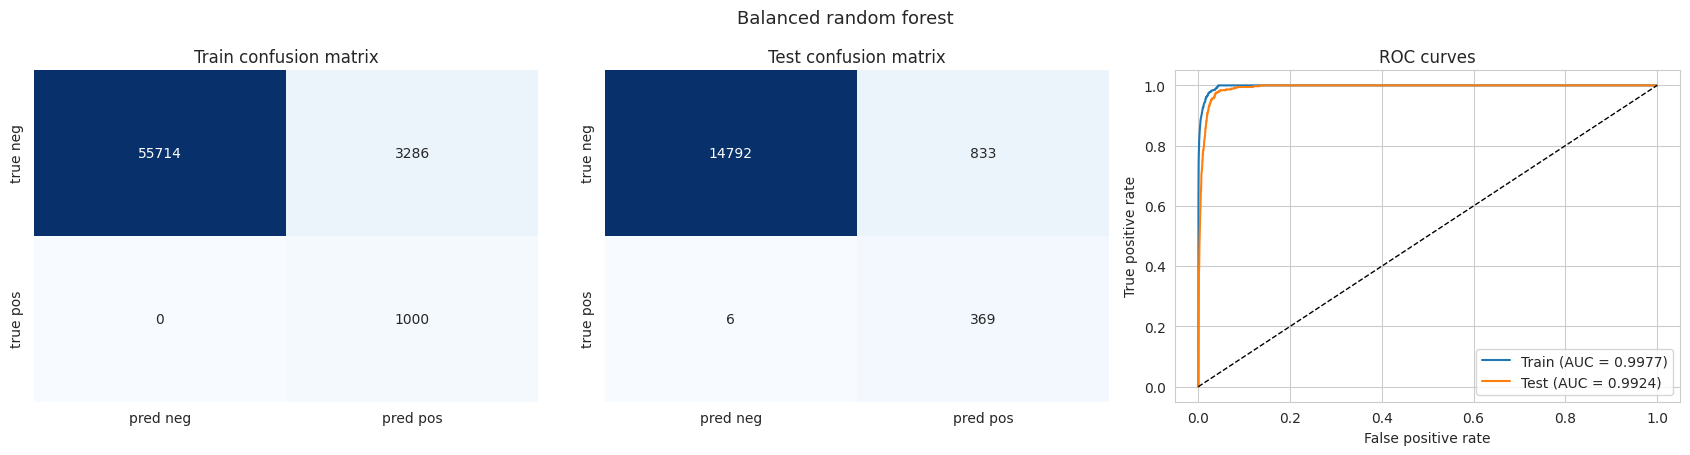

,TN,FP,FN,TP,misclassification,AUC,recall (pos),precision (pos),cost (10·FP + 500·FN)
set,,,,,,,,,
Train,55714,3286,0,1000,0.0548,0.9977,1.0000,0.2333,32860
Test,14792,833,6,369,0.0524,0.9924,0.9840,0.3070,11330


Valid OOB predictions: 57,358/60,000 (95.60%)
OOB error on covered observations: 0.05715


In [13]:
# Method 1: Balanced random forest (each tree is grown on a class-balanced bootstrap sample)
brf = BalancedRandomForestClassifier(n_estimators=500, max_features="sqrt",
                                     sampling_strategy="auto", replacement=False,
                                     bootstrap=True, oob_score=True,
                                     n_jobs=-1, random_state=SEED)
brf.fit(X_train, y_train)
brf_res = evaluate(brf, "Balanced random forest")

print(f"Library OOB error (includes rows without OOB votes): {1 - brf.oob_score_:.4f}")
print(f"Test error:         {brf_res.loc['Test', 'misclassification']:.4f}")

# Exclude observations for which this balanced forest produced no OOB prediction.
oob_prob = brf.oob_decision_function_
valid_oob = np.isfinite(oob_prob).all(axis=1) & (oob_prob.sum(axis=1) > 0)
brf_valid_oob_error = 1 - accuracy_score(y_train[valid_oob], oob_prob[valid_oob].argmax(axis=1))
print(f"Valid OOB predictions: {valid_oob.sum():,}/{len(y_train):,} ({valid_oob.mean():.2%})")
print(f"OOB error on covered observations: {brf_valid_oob_error:.5f}")


OOB error estimate: 0.0076
Test error:         0.0107


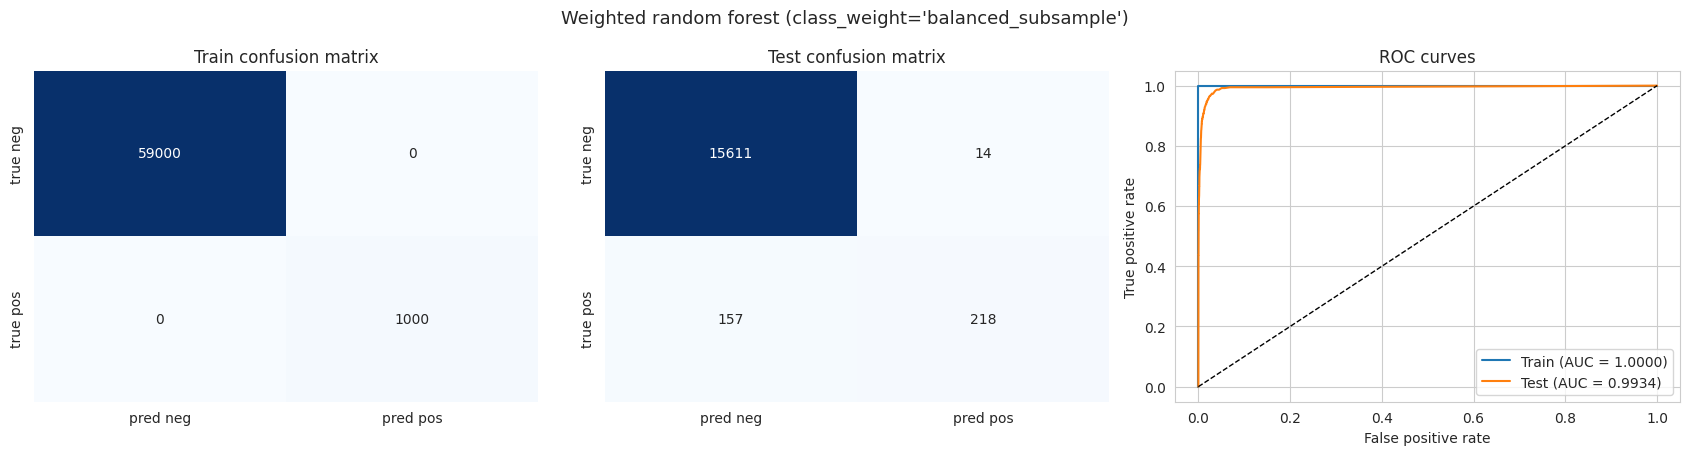

,TN,FP,FN,TP,misclassification,AUC,recall (pos),precision (pos),cost (10·FP + 500·FN)
set,,,,,,,,,
Train,59000,0,0,1000,0.0000,1.0000,1.0000,1.0000,0
Test,15611,14,157,218,0.0107,0.9934,0.5813,0.9397,78640


In [14]:
# Method 2: Weighted (cost-sensitive) random forest, class weights inversely proportional
# to class frequencies in each bootstrap sample
wrf = RandomForestClassifier(n_estimators=300, max_features="sqrt", oob_score=True,
                             class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
wrf.fit(X_train, y_train)
wrf_res = evaluate(wrf, "Weighted random forest (class_weight='balanced_subsample')")

print(f"OOB error estimate: {1 - wrf.oob_score_:.4f}")
print(f"Test error:         {wrf_res.loc['Test', 'misclassification']:.4f}")

In [15]:
cmp_rf = pd.DataFrame({k: results[k] for k in ["Random forest (uncompensated)", "Balanced random forest",
                                               "Weighted random forest (class_weight='balanced_subsample')"]}).T
with pd.option_context("display.float_format", "{:.4f}".format):
    display(cmp_rf[["TN", "FP", "FN", "TP", "misclassification", "AUC", "recall (pos)", "cost (10·FP + 500·FN)"]])

,TN,FP,FN,TP,misclassification,AUC,recall (pos),cost (10·FP + 500·FN)
Random forest (uncompensated),15607.0000,18.0000,104.0000,271.0000,0.0076,0.9942,0.7227,52180.0000
Balanced random forest,14792.0000,833.0000,6.0000,369.0000,0.0524,0.9924,0.9840,11330.0000
Weighted random forest (class_weight='balanced_subsample'),15611.0000,14.0000,157.0000,218.0000,0.0107,0.9934,0.5813,78640.0000


**Comparison with part (c)**

| Model / set | TN | FP | FN | TP | Error | AUC | Recall | Cost |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Uncompensated RF | 15,607 | 18 | 104 | 271 | 0.00762 | 0.99422 | 0.7227 | 52,180 |
| Balanced RF | 14,792 | 833 | 6 | 369 | 0.05244 | 0.99236 | 0.9840 | 11,330 |
| Weighted RF | 15,611 | 14 | 157 | 218 | 0.01069 | 0.99342 | 0.5813 | 78,640 |

Balanced RF: OOB error on covered observations **0.05715**, test error **0.05244**. Weighted RF: OOB error **0.00762**, test error **0.01069**.

The table shows the trade-off between false alarms and missed failures. Lower overall error does not necessarily mean lower cost when false negatives cost 50 times as much as false positives. Balancing can improve minority recall while increasing the number of false alarms. Class weighting changes split calculations and leaf probabilities, but does not guarantee higher recall at a fixed threshold; the observed effect should be judged from the table rather than assumed.

Balanced RF uses only a subset of majority observations for each tree, so individual majority observations may receive relatively few OOB predictions. Its OOB estimate should be interpreted with that limitation. As in part (c), imputation was fitted on the full training set.

For balanced RF, 2,642 of 60,000 training observations have no OOB votes. The library's raw OOB error (0.05463) includes these undefined predictions. The covered-only error above uses 57,358 observations (95.60% coverage); it is not an error estimate on all 60,000 rows, and coverage may differ across classes.

## (e) XGBoost and model trees

The implementation uses **gradient-boosted trees with binary logistic loss and an L1 penalty on leaf scores** (`booster="gbtree"`, `objective="binary:logistic"`, `reg_alpha=alpha`). The predicted probability is the logistic transformation of the ensemble's raw score. `reg_lambda=0` disables the L2 penalty.

The assignment describes a logistic-regression model at each node, but this is not what the standard XGBoost tree booster implements. Its nodes use feature splits and its leaves have scalar scores; L1 regularization applies to those scores rather than a vector of logistic-regression coefficients at each node. This implementation interprets the XGBoost requirement as L1-regularized boosted trees with logistic loss. A linear booster would instead fit a global linear model and would not implement node-wise logistic regression either.

**Choosing alpha.** Five-fold stratified CV compares positive alpha values `{0.01, 0.1, 0.5, 1, 5, 10, 100}`. Alpha is selected by mean validation ROC AUC; misclassification error is also reported. Median imputation is fitted separately inside each training fold. No balancing or class weighting is used. Other settings are 200 trees, depth 6 and learning rate 0.1.

The reported CV score is the score used for hyperparameter selection, not a separate unbiased estimate of the entire tuning procedure. The untouched test set provides the final evaluation; nested CV would be needed for an independent CV estimate of tuning performance.

In [16]:
alphas = [0.01, 0.1, 0.5, 1, 5, 10, 100]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_xgb(alpha):
    return XGBClassifier(objective="binary:logistic", booster="gbtree", reg_alpha=alpha, reg_lambda=0,
                         n_estimators=200, max_depth=6, learning_rate=0.1, tree_method="hist",
                         eval_metric="logloss", n_jobs=4, random_state=SEED)

def make_imputed_xgb(alpha):
    return Pipeline([("imputer", SimpleImputer(strategy="median")), ("xgb", make_xgb(alpha))])

cv_rows = []
for a in alphas:
    s = cross_validate(make_imputed_xgb(a), X_train_raw, y_train, cv=skf, scoring=["accuracy", "roc_auc"], n_jobs=1)
    cv_rows.append({"alpha": a, "CV error": 1 - s["test_accuracy"].mean(),
                    "CV error std": s["test_accuracy"].std(), "CV AUC": s["test_roc_auc"].mean()})
cv_xgb = pd.DataFrame(cv_rows).set_index("alpha")
with pd.option_context("display.float_format", "{:.5f}".format):
    display(cv_xgb)

best_alpha = cv_xgb["CV AUC"].idxmax()
print(f"Best alpha (highest 5-fold CV AUC): {best_alpha}")

Best alpha (highest 5-fold CV AUC): 0.5


,CV error,CV error std,CV AUC
alpha,,,
0.01000,0.00578,0.00062,0.98819
0.10000,0.00565,0.00044,0.98794
0.50000,0.00570,0.00060,0.98905
1.00000,0.00560,0.00073,0.98838
5.00000,0.00638,0.00047,0.98822
10.00000,0.00683,0.00073,0.98865
100.00000,0.01127,0.00059,0.98186


5-fold CV error estimate: 0.0057
Test error:               0.0068


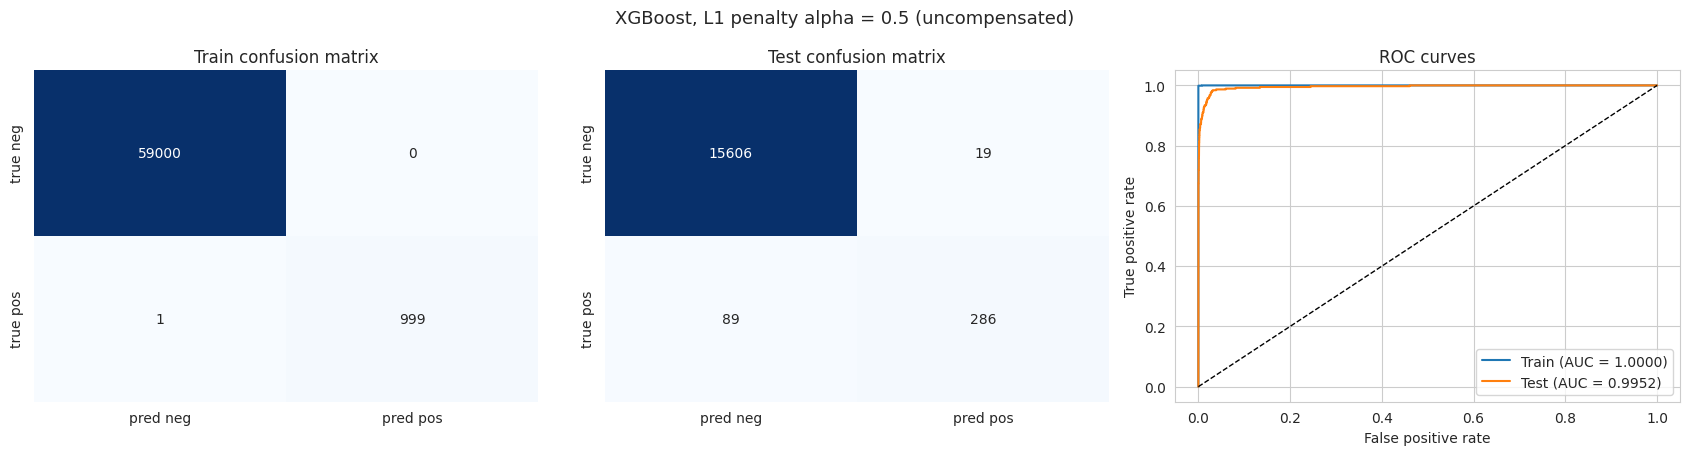

,TN,FP,FN,TP,misclassification,AUC,recall (pos),precision (pos),cost (10·FP + 500·FN)
set,,,,,,,,,
Train,59000,0,1,999,0.0000,1.0000,0.9990,1.0000,500
Test,15606,19,89,286,0.0068,0.9952,0.7627,0.9377,44690


In [17]:
xgb = make_imputed_xgb(best_alpha).fit(X_train_raw, y_train)
xgb_res = evaluate(xgb, f"XGBoost, L1 penalty alpha = {best_alpha} (uncompensated)", X_tr=X_train_raw)

print(f"5-fold CV error estimate: {cv_xgb.loc[best_alpha, 'CV error']:.4f}")
print(f"Test error:               {xgb_res.loc['Test', 'misclassification']:.4f}")

**Results: L1-regularized XGBoost without balancing**

Five-fold CV selects **alpha = 0.5** by mean CV AUC **0.98905**. CV misclassification is **0.00570**, versus held-out test error **0.00675**.

| Model / set | TN | FP | FN | TP | Error | AUC | Recall | Cost |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Train | 59,000 | 0 | 1 | 999 | 0.00002 | 0.99999 | 0.9990 | 500 |
| Test | 15,606 | 19 | 89 | 286 | 0.00675 | 0.99524 | 0.7627 | 44,690 |

The CV score comes from fold-local median imputation. It is a tuning score, so selecting the best alpha on these same folds can introduce selection optimism. Test results are evaluated only after alpha is chosen. Differences in class proportions, sampling variability and other distribution differences may contribute to the CV/test gap.

Compared with the uncompensated RF, XGBoost has test error 0.00675 versus 0.00762, AUC 0.99524 versus 0.99422, and 89 versus 104 false negatives. These are results from one fixed test split, not evidence of a statistically established difference.

## (f) SMOTE + XGBoost

SMOTE interpolates between minority-class observations and their nearest minority neighbors. On the full training set, it increases the positive class from 1,000 to 59,000, producing 118,000 observations in total.

**Cross-validation:** each training fold fits `median imputation → standardization → SMOTE → XGBoost`. The validation fold is transformed using the training-fold imputer and scaler, but is never oversampled. Standardization prevents large-unit features from dominating SMOTE's Euclidean neighbor distances. Although trees do not require scaling, SMOTE depends on those distances.

Applying SMOTE before splitting would allow related synthetic/original observations into both training and validation folds and would change the validation class balance. Likewise, computing medians or scaling statistics before splitting would leak validation information. All three operations therefore belong inside the pipeline.

Alpha is selected by five-fold CV AUC using the same grid as part (e). The final pipeline is fitted to all original training rows and evaluated on the original 60,000 training observations and the held-out test set. Test missing values are filled with test medians as required by the assignment footnote; the scaler remains fitted only to training data.

In [18]:
def make_smote_xgb(alpha):
    return ImbPipeline([("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()),
                        ("smote", SMOTE(random_state=SEED)),
                        ("xgb", make_xgb(alpha))])

cv_rows = []
for a in alphas:
    s = cross_validate(make_smote_xgb(a), X_train_raw, y_train, cv=skf, scoring=["accuracy", "roc_auc"], n_jobs=1)
    cv_rows.append({"alpha": a, "CV error": 1 - s["test_accuracy"].mean(),
                    "CV error std": s["test_accuracy"].std(), "CV AUC": s["test_roc_auc"].mean()})
cv_smote = pd.DataFrame(cv_rows).set_index("alpha")
with pd.option_context("display.float_format", "{:.5f}".format):
    display(cv_smote)

best_alpha_s = cv_smote["CV AUC"].idxmax()
print(f"Best alpha (highest 5-fold CV AUC, SMOTE inside each training fold): {best_alpha_s}")

Best alpha (highest 5-fold CV AUC, SMOTE inside each training fold): 10.0


,CV error,CV error std,CV AUC
alpha,,,
0.01000,0.00695,0.00058,0.98753
0.10000,0.00710,0.00068,0.98683
0.50000,0.00702,0.00060,0.98676
1.00000,0.00693,0.00067,0.98740
5.00000,0.00747,0.00057,0.98730
10.00000,0.00820,0.00052,0.98760
100.00000,0.01880,0.00084,0.98648


After SMOTE: (118000, 170) class counts: [59000 59000]
5-fold CV error estimate: 0.00820
Test error: 0.01262


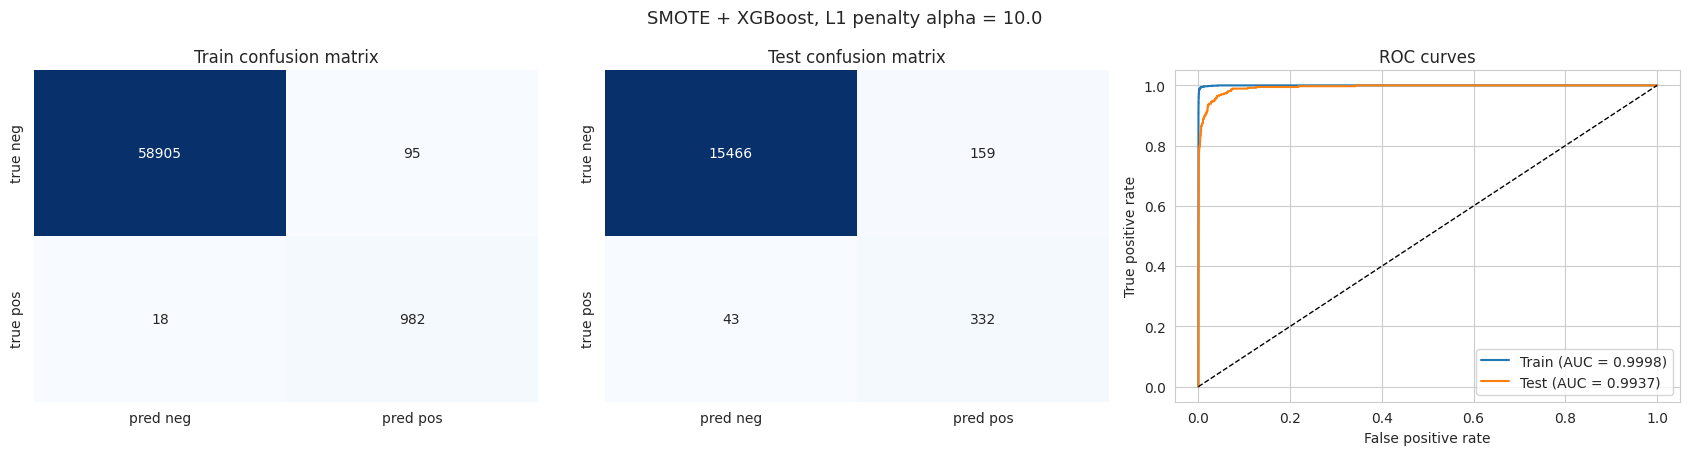

,TN,FP,FN,TP,misclassification,AUC,recall (pos),precision (pos),cost (10·FP + 500·FN)
set,,,,,,,,,
Train,58905,95,18,982,0.0019,0.9998,0.9820,0.9118,9950
Test,15466,159,43,332,0.0126,0.9937,0.8853,0.6762,23090


In [19]:
# Fit all preprocessing and SMOTE on the complete training set only.
xgb_sm = make_smote_xgb(best_alpha_s).fit(X_train_raw, y_train)
original_counts = np.bincount(y_train)
added = xgb_sm.named_steps["smote"].sampling_strategy_
resampled_counts = original_counts.copy()
for label, number in added.items():
    resampled_counts[label] += number
print("After SMOTE:", (int(resampled_counts.sum()), X_train_raw.shape[1]),
      "class counts:", resampled_counts)
sm_res = evaluate(xgb_sm, f"SMOTE + XGBoost, L1 penalty alpha = {best_alpha_s}", X_tr=X_train_raw)
print(f"5-fold CV error estimate: {cv_smote.loc[best_alpha_s, 'CV error']:.5f}")
print(f"Test error: {sm_res.loc['Test', 'misclassification']:.5f}")

The validation folds retain the original class distribution. No test rows or labels are used to choose alpha or generate synthetic observations.

In [20]:
summary = pd.DataFrame(results).T
summary.index.name = "model (test set)"
with pd.option_context("display.float_format", "{:.4f}".format):
    display(summary[["TN", "FP", "FN", "TP", "misclassification", "AUC",
                     "recall (pos)", "precision (pos)", "cost (10·FP + 500·FN)"]])

,TN,FP,FN,TP,misclassification,AUC,recall (pos),precision (pos),cost (10·FP + 500·FN)
model (test set),,,,,,,,,
Random forest (uncompensated),15607.0000,18.0000,104.0000,271.0000,0.0076,0.9942,0.7227,0.9377,52180.0000
Balanced random forest,14792.0000,833.0000,6.0000,369.0000,0.0524,0.9924,0.9840,0.3070,11330.0000
Weighted random forest (class_weight='balanced_subsample'),15611.0000,14.0000,157.0000,218.0000,0.0107,0.9934,0.5813,0.9397,78640.0000
"XGBoost, L1 penalty alpha = 0.5 (uncompensated)",15606.0000,19.0000,89.0000,286.0000,0.0068,0.9952,0.7627,0.9377,44690.0000
"SMOTE + XGBoost, L1 penalty alpha = 10.0",15466.0000,159.0000,43.0000,332.0000,0.0126,0.9937,0.8853,0.6762,23090.0000


**Results: SMOTE + L1-regularized XGBoost**

Fold-local imputation, scaling and SMOTE select **alpha = 10**. Mean CV AUC is **0.98760** and CV error is **0.00820**, compared with test error **0.01262**.

| Model / set | TN | FP | FN | TP | Error | AUC | Recall | Cost |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Train | 58,905 | 95 | 18 | 982 | 0.00188 | 0.99979 | 0.9820 | 9,950 |
| Test | 15,466 | 159 | 43 | 332 | 0.01262 | 0.99373 | 0.8853 | 23,090 |

**Comparison with part (e)**

| Model / set | TN | FP | FN | TP | Error | AUC | Recall | Cost |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Uncompensated XGBoost | 15,606 | 19 | 89 | 286 | 0.00675 | 0.99524 | 0.7627 | 44,690 |
| SMOTE + XGBoost | 15,466 | 159 | 43 | 332 | 0.01262 | 0.99373 | 0.8853 | 23,090 |

Test recall changes from 76.27% to 88.53%, precision from 93.77% to 67.62%, false negatives from 89 to 43, and false positives from 19 to 159. Cost changes from 44,690 to 23,090 (48.3% reduction).

These results describe the trade-off at a fixed probability threshold of 0.5. Resampling changes the learned model and is not mathematically equivalent to lowering a decision threshold. The AUC comparison evaluates ranking, while the confusion matrices and costs evaluate decisions at the selected threshold.

The full-model comparison is shown in the preceding table. The preferred model depends on whether the objective is low overall error, high minority recall, high precision, or the supplied cost function. Any further threshold or model selection should use training/validation data, not repeated optimization on this test set.

# 2. ISLR 6.6.3

We estimate the coefficients by minimizing
$$\sum_{i=1}^{n}\Big(y_i-\beta_0-\sum_{j=1}^{p}\beta_jx_{ij}\Big)^2 \quad\text{subject to}\quad \sum_{j=1}^{p}|\beta_j|\le s.$$
This is the lasso. As $s$ grows from 0, the constraint becomes looser. At $s=0$ all $\beta_j=0$ (only the intercept, a very inflexible model). For large enough $s$ the constraint is inactive and we get the least-squares solution (the most flexible model). So increasing $s$ means increasing model flexibility.

**(a) Training RSS: (iv) Steadily decrease.** As $s$ increases, the feasible set gets larger and contains all the earlier feasible sets, so the minimum training RSS can only go down (or stay the same), until it reaches the least-squares RSS.

**(b) Test RSS: (ii) Decrease initially, and then eventually start increasing in a U shape.** At first, letting the coefficients grow reduces bias much more than it increases variance, so test RSS falls. After some point the model starts to overfit, the increase in variance dominates, and test RSS rises again.

**(c) Variance: (iii) Steadily increase.** At $s=0$ the fitted prediction is the sample mean, so it still has sampling variance (under independent homoskedastic errors, $\sigma^2/n$). As $s$ increases, the coefficients depend more and more on the particular training sample, so variance increases.

**(d) (Squared) bias: (iv) Steadily decrease.** A more flexible model can approximate the true relationship better, so squared bias decreases as $s$ increases (reaching its minimum at the least-squares fit).

**(e) Irreducible error: (v) Remain constant.** The irreducible error $\mathrm{Var}(\epsilon)$ is a property of the data-generating process and does not depend on the model or on $s$.

# 3. ISLR 6.6.5

Setup: $n=2$, $p=2$, $x_{11}=x_{12}$, $x_{21}=x_{22}$, $y_1+y_2=0$, $x_{11}+x_{21}=0$, $x_{12}+x_{22}=0$, so the least-squares intercept is $\hat\beta_0=0$.

For convenience write $x_{11}=x_{12}=x$, so $x_{21}=x_{22}=-x$, and $y_2=-y_1$, with $x\neq 0$.

**(a) Ridge regression optimization problem**
$$\min_{\beta_1,\beta_2}\; \big(y_1-\beta_1x_{11}-\beta_2x_{12}\big)^2+\big(y_2-\beta_1x_{21}-\beta_2x_{22}\big)^2+\lambda\big(\beta_1^2+\beta_2^2\big).$$

**(b) Ridge estimates satisfy $\hat\beta_1=\hat\beta_2$**

Substituting the setup, both residuals have the same square:
$\big(y_1-x(\beta_1+\beta_2)\big)^2$ and $\big(-y_1+x(\beta_1+\beta_2)\big)^2$. So the objective is
$$f(\beta_1,\beta_2)=2\big(y_1-x(\beta_1+\beta_2)\big)^2+\lambda(\beta_1^2+\beta_2^2).$$
Setting the partial derivatives to zero:
$$\frac{\partial f}{\partial\beta_1}=-4x\big(y_1-x(\beta_1+\beta_2)\big)+2\lambda\beta_1=0,\qquad
\frac{\partial f}{\partial\beta_2}=-4x\big(y_1-x(\beta_1+\beta_2)\big)+2\lambda\beta_2=0.$$
Subtracting the two equations gives $2\lambda(\beta_1-\beta_2)=0$, and since $\lambda>0$, $\hat\beta_1=\hat\beta_2$. (The objective is strictly convex for $\lambda>0$, so this stationary point is the unique minimizer.) Plugging $\beta_1=\beta_2=\beta$ back in: $-4xy_1+8x^2\beta+2\lambda\beta=0$, so
$$\hat\beta_1=\hat\beta_2=\frac{2xy_1}{4x^2+\lambda}.$$

**(c) Lasso optimization problem**
$$\min_{\beta_1,\beta_2}\; \big(y_1-\beta_1x_{11}-\beta_2x_{12}\big)^2+\big(y_2-\beta_1x_{21}-\beta_2x_{22}\big)^2+\lambda\big(|\beta_1|+|\beta_2|\big).$$

**(d) The lasso coefficients are not unique**

With the same substitution the lasso objective is
$$g(\beta_1,\beta_2)=2\big(y_1-x(\beta_1+\beta_2)\big)^2+\lambda\big(|\beta_1|+|\beta_2|\big).$$
The RSS term depends only on the sum $t=\beta_1+\beta_2$. For a fixed $t$, the penalty satisfies $|\beta_1|+|\beta_2|\ge|t|$, with equality exactly when $\beta_1$ and $\beta_2$ have the same sign (or one is 0). So the problem reduces to the one-dimensional lasso
$$\min_t\; 2(y_1-xt)^2+\lambda|t|,$$
whose solution is the soft-thresholded value
$$\hat t=\frac{\operatorname{sign}(xy_1)\,\big(|xy_1|-\lambda/4\big)_+}{x^2}.$$
Every pair with $\beta_1+\beta_2=\hat t$ and $\beta_1,\beta_2$ of the same sign as $\hat t$ is a solution. For example, if $\hat t>0$ the solution set is the whole line segment
$$\{(\beta_1,\beta_2):\ \beta_1+\beta_2=\hat t,\ \beta_1\ge0,\ \beta_2\ge0\},$$
and if $\hat t<0$ it is the segment $\beta_1+\beta_2=\hat t$ with $\beta_1,\beta_2\le0$ (if $|xy_1|\le\lambda/4$, the unique solution is $\beta_1=\beta_2=0$).

**Geometric view.** The RSS contours are the lines $\beta_1+\beta_2=\text{constant}$, which are parallel to two edges of the lasso diamond $|\beta_1|+|\beta_2|\le s$ (the edges $\beta_1+\beta_2=\pm s$). For a nonzero optimal coefficient sum, the minimum is attained by a line segment of coefficient pairs with that sum. When the penalty is sufficiently large to make the optimal sum zero, the penalized problem instead has the unique solution (0, 0).

# 4. ISLR 8.4.5

Ten bootstrapped trees give $P(\text{Class is Red}\mid X)$:
$0.1,\ 0.15,\ 0.2,\ 0.2,\ 0.55,\ 0.6,\ 0.6,\ 0.65,\ 0.7,\ 0.75$.

**Majority vote approach:** each tree predicts Red if its probability is greater than 0.5. Six trees (0.55, 0.6, 0.6, 0.65, 0.7, 0.75) predict Red and four predict Green, so the final classification is **Red**.

**Average probability approach:** the average probability is $(0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75)/10 = 4.5/10 = 0.45 < 0.5$, so the final classification is **Green**.

The two approaches disagree because the four trees that vote Green are very confident (probabilities 0.1 to 0.2), while the six Red votes are only moderately confident.

In [21]:
p = np.array([0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75])
print("Votes for Red (P > 0.5):", (p > 0.5).sum(), "of", len(p), "-> majority vote:",
      "Red" if (p > 0.5).sum() > len(p) / 2 else "Green")
print("Average probability:", p.mean(), "-> average-probability rule:", "Red" if p.mean() > 0.5 else "Green")

Votes for Red (P > 0.5): 6 of 10 -> majority vote: Red
Average probability: 0.45 -> average-probability rule: Green


# 5. ISLR 9.7.3

| Obs. | $X_1$ | $X_2$ | $Y$ |
|---|---|---|---|
| 1 | 3 | 4 | Red |
| 2 | 2 | 2 | Red |
| 3 | 4 | 4 | Red |
| 4 | 1 | 4 | Red |
| 5 | 2 | 1 | Blue |
| 6 | 4 | 3 | Blue |
| 7 | 4 | 1 | Blue |

**(a) Sketch of the observations**

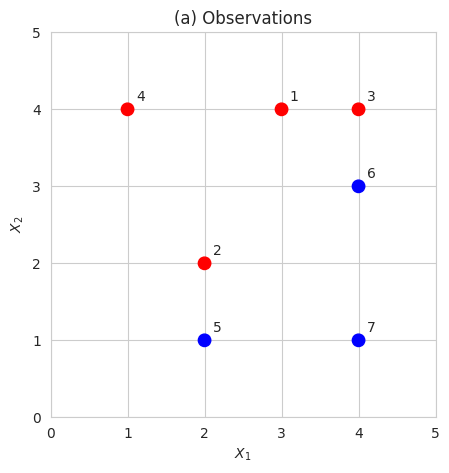

In [22]:
X93 = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
y93 = np.array(["Red", "Red", "Red", "Red", "Blue", "Blue", "Blue"])
colors = np.where(y93 == "Red", "red", "blue")

def base_plot(ax, title):
    ax.scatter(X93[:, 0], X93[:, 1], c=colors, s=80, zorder=3)
    for i, (a, b) in enumerate(X93, start=1):
        ax.annotate(str(i), (a, b), textcoords="offset points", xytext=(6, 6))
    ax.set_xlim(0, 5); ax.set_ylim(0, 5); ax.set_aspect("equal")
    ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$"); ax.set_title(title)

fig, ax = plt.subplots(figsize=(5, 5))
base_plot(ax, "(a) Observations")
plt.show()

**(b) Optimal separating hyperplane**

The closest pairs of opposite-class points are Red (2,2) with Blue (2,1), and Red (4,4) with Blue (4,3). The Red points (2,2) and (4,4) lie on the line $X_2=X_1$, and the Blue points (2,1) and (4,3) lie on the parallel line $X_2=X_1-1$. The maximal margin hyperplane is the line halfway between them:
$$X_2 = X_1 - 0.5, \qquad\text{i.e.}\qquad 0.5 - X_1 + X_2 = 0.$$
The cell below also checks this with a linear SVM with a very large cost (which approximates the hard-margin solution for these separable data).

classes: ['Blue' 'Red']
SVM hyperplane (rescaled): 0.500 + (-1.000) X1 + 1.000 X2 = 0
Support vectors: [[2.0, 1.0], [4.0, 3.0], [2.0, 2.0], [4.0, 4.0]]
Margin (distance from hyperplane to support vectors): 0.35365700104279774  vs sqrt(2)/4 = 0.3535533905932738


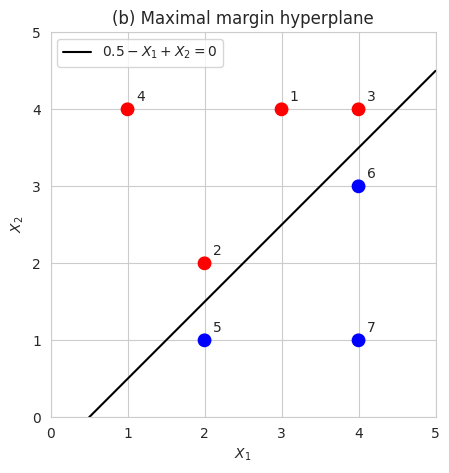

In [23]:
from sklearn.svm import SVC

svm93 = SVC(kernel="linear", C=1e6).fit(X93, y93)
w, b = svm93.coef_[0], svm93.intercept_[0]
# classes_ = ['Blue', 'Red'], so a positive decision value means Red.
# Rescale so that the coefficient of X2 is 1.
print("classes:", svm93.classes_)
print(f"SVM hyperplane (rescaled): {b / w[1]:.3f} + ({w[0] / w[1]:.3f}) X1 + 1.000 X2 = 0")
print("Support vectors:", svm93.support_vectors_.tolist())
print("Margin (distance from hyperplane to support vectors):", 1 / np.linalg.norm(w), " vs sqrt(2)/4 =", np.sqrt(2) / 4)

xs = np.linspace(0, 5, 100)
fig, ax = plt.subplots(figsize=(5, 5))
base_plot(ax, "(b) Maximal margin hyperplane")
ax.plot(xs, xs - 0.5, "k-", label="$0.5 - X_1 + X_2 = 0$")
ax.legend(loc="upper left")
plt.show()

**(c) Classification rule**

Classify to **Red if $0.5 - X_1 + X_2 > 0$**, and classify to **Blue otherwise** (ties on the hyperplane are assigned to Blue). In the notation of the book, $\beta_0 = 0.5$, $\beta_1 = -1$, $\beta_2 = 1$. (Normalized so that $\beta_1^2+\beta_2^2=1$: $\beta_0=\tfrac{0.5}{\sqrt2}\approx0.354$, $\beta_1=-\tfrac{1}{\sqrt2}\approx-0.707$, $\beta_2=\tfrac{1}{\sqrt2}\approx0.707$.)

Check: Red points have $X_2-X_1\ge0$, so $0.5-X_1+X_2\ge0.5>0$; Blue points have $X_2-X_1\le-1$, so $0.5-X_1+X_2\le-0.5<0$.

**(d) Margin**

The margin boundaries are the parallel lines through the support vectors, $X_2 = X_1$ and $X_2 = X_1 - 1$ (dashed lines in the plot below). The margin, i.e. the distance from the hyperplane to either boundary, is
$$M=\frac{|0.5|}{\sqrt{1^2+1^2}}=\frac{0.5}{\sqrt2}=\frac{\sqrt2}{4}\approx0.354.$$

**(e) Support vectors**

The support vectors are the points on the margin boundaries: **observations 2 (2,2), 3 (4,4), 5 (2,1) and 6 (4,3)** (circled in the plot).

**(f) Moving the seventh observation**

Observation 7, (4,1), is not a support vector. Its distance to the hyperplane is $|0.5-4+1|/\sqrt2 = 2.5/\sqrt2\approx1.77$, which is much larger than the margin $0.354$. The maximal margin hyperplane depends only on the support vectors, so a slight movement of observation 7 (that keeps it outside the margin, on the Blue side) does not change the hyperplane.

**(g) A separating hyperplane that is not optimal**

For example, $0.1 - X_1 + X_2 = 0$ (dotted line in the plot below). It still separates the classes (Red points give values $\ge 0.1>0$, Blue points give values $\le-0.9<0$), but it is much closer to the Red points (2,2) and (4,4): its margin is only $0.1/\sqrt2\approx0.071$, smaller than the optimal $0.354$.

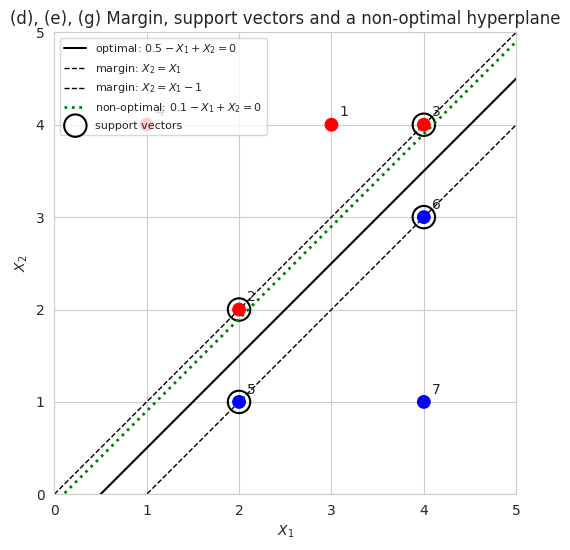

In [24]:
fig, ax = plt.subplots(figsize=(6, 6))
base_plot(ax, "(d), (e), (g) Margin, support vectors and a non-optimal hyperplane")
ax.plot(xs, xs - 0.5, "k-", label="optimal: $0.5 - X_1 + X_2 = 0$")
ax.plot(xs, xs, "k--", lw=1, label="margin: $X_2 = X_1$")
ax.plot(xs, xs - 1, "k--", lw=1, label="margin: $X_2 = X_1 - 1$")
ax.plot(xs, xs - 0.1, "g:", lw=2, label="non-optimal: $0.1 - X_1 + X_2 = 0$")
sv = np.array([[2, 2], [4, 4], [2, 1], [4, 3]])
ax.scatter(sv[:, 0], sv[:, 1], s=260, facecolors="none", edgecolors="k", linewidths=1.5, label="support vectors")
ax.legend(loc="upper left", fontsize=8)
plt.show()

**(h) An additional observation that makes the classes non-separable**

Add a **Red** observation at **(4, 2)**. It lies on the segment between the two Blue points (4,1) and (4,3). Any line that has both of those Blue points strictly on one side also has every point of the segment between them, including (4,2), on that same side. So no hyperplane can put (4,2) on the Red side while keeping all Blue points on the Blue side, and the two classes are no longer separable by a hyperplane.

Training accuracy of finite-C soft-margin linear SVM after adding (4, 2): 0.625


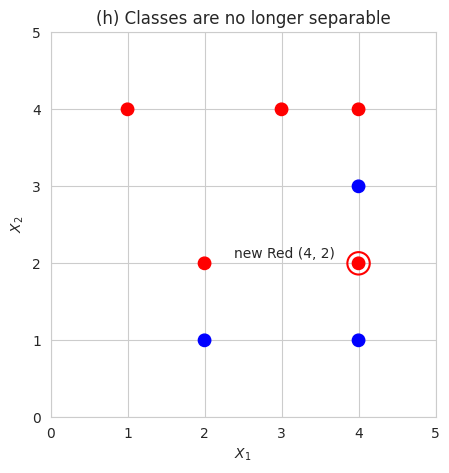

In [25]:
X93h = np.vstack([X93, [4, 2]])
y93h = np.append(y93, "Red")
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X93h[:, 0], X93h[:, 1], c=np.where(y93h == "Red", "red", "blue"), s=80, zorder=3)
ax.scatter([4], [2], s=260, facecolors="none", edgecolors="red", linewidths=1.5)
ax.annotate("new Red (4, 2)", (4, 2), textcoords="offset points", xytext=(-90, 4))
ax.set_xlim(0, 5); ax.set_ylim(0, 5); ax.set_aspect("equal")
ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$"); ax.set_title("(h) Classes are no longer separable")
plt.show()

# Illustration using a finite-C soft-margin linear SVM; the geometric argument proves non-separability.
svm_h = SVC(kernel="linear", C=1e6).fit(X93h, y93h)
print("Training accuracy of finite-C soft-margin linear SVM after adding (4, 2):", svm_h.score(X93h, y93h))

## References

- UCI Machine Learning Repository, APS Failure at Scania Trucks dataset and supplied description.
- [scikit-learn: common pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html).
- [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html).
- [imbalanced-learn: SMOTE](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html).
- [imbalanced-learn: balanced random forest](https://imbalanced-learn.org/stable/references/generated/imblearn.ensemble.BalancedRandomForestClassifier.html).
- Chen, C., Liaw, A. and Breiman, L. (2004). *Using Random Forest to Learn Imbalanced Data*. UC Berkeley, Technical Report 666.
- James, G., Witten, D., Hastie, T. and Tibshirani, R. *An Introduction to Statistical Learning*.